# Стадия 6. Пайплайны, схемы проверки и альтернативные инструменты подбора

**Данные:** `data/processed/train_model.parquet` (результат стадии 1); описание набора — `README.md`.
**Предыдущие этапы:** `Stage_3_classification.ipynb` — базовая модель;
`Stage_4_polynomial_regularization.ipynb` — полиномиальные признаки и штрафы;
`Stage_5_optuna.ipynb` — сетка против байесовской оптимизации.

**Цель стадии.** Собрать разрозненные приёмы проверки и подбора в один воспроизводимый
объект — пайплайн, — и на его основе ответить на три вопроса:

1. Насколько вообще устойчива оценка качества к случайности разбиения, и какие из
   полученных в стадиях 3–5 приростов превышают этот шум.
2. Какие схемы проверки применимы к нашей задаче с редким классом `CL` и чем они различаются.
3. Чем отличаются четыре инструмента подбора гиперпараметров — полный перебор, случайный
   поиск, ранний отсев и их комбинация — на одинаковых данных, одинаковой схеме проверки
   и одинаковом критерии.

**Итог стадии.** Рекомендация модели к применению с обоснованием: качество, устойчивость
и цена подбора.

**Зачем это нужно.** В стадиях 4 и 5 стандартизация выполнялась до разбиения на блоки
кросс-валидации, а матрицы признаков готовились вручную для каждой степени полинома.
Приём рабочий, но он не оформлен в единый объект и требует ручной пересборки при каждом
переносе модели в эксплуатацию. Пайплайн решает обе задачи: все преобразования
выполняются внутри каждого блока проверки и переносятся вместе с моделью.

## **1. Импорты и настройки**

In [1]:
# Сторонние библиотеки
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, uniform
# HalvingGridSearchCV и HalvingRandomSearchCV в scikit-learn 1.9 помечены как экспериментальные:
# импорт enable_halving_search_cv должен предшествовать импорту самих классов
from sklearn.experimental import enable_halving_search_cv   # noqa: F401
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             log_loss, recall_score)
from sklearn.model_selection import (GridSearchCV, HalvingGridSearchCV,
                                     HalvingRandomSearchCV, KFold, LeaveOneOut,
                                     RandomizedSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_score,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

# Единое зерно случайности для всего ноутбука: выборки, разбиения, кросс-валидация.
# Значение не меняется между прогонами и стадиями, поэтому результаты сравнимы.
RANDOM_STATE = 42

## **2. Данные и точка отсчёта**

Матрица, разбиение и зерно — те же, что в стадиях 3, 4 и 5: 15 отобранных признаков,
контрольная часть 25 %, стратификация по классам, `RANDOM_STATE = 42`. Отличие стадии 6:
стандартизация больше не выполняется вручную, она внутри пайплайна. Базовая модель
воспроизводится и сверяется с числами стадии 3 — это подтверждает, что пайплайн
эквивалентен ручной предобработке и сравнение со всеми предыдущими стадиями корректно.

In [2]:
# Корень проекта: папка с data/, найденная вверх по дереву от текущей директории
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent


PROJECT_ROOT = find_project_root()
df = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_model.parquet'))
assert df.shape == (7905, 16), 'Ожидается матрица 7 905 x 16 из стадии 1'
assert df.isna().sum().sum() == 0, 'В матрице модели не должно быть пропусков'

X = df.drop(columns=['Status']).astype(float)
y = df['Status'].astype(str)
assert X.shape[1] == 15, 'В матрице должно быть 15 отобранных признаков'

# Основное разбиение — то же, что в стадиях 3, 4 и 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print('Обучающая часть:', X_train.shape[0], 'строк / контрольная:', X_test.shape[0])
print('Класс CL в контрольной части:', int((y_test == 'CL').sum()), 'из', len(y_test))


def evaluate(model, X_eval, y_eval, tag):
    # Набор метрик классификации — тот же, что в стадиях 3, 4 и 5.
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    return {
        'вариант': tag,
        'доля верных ответов': accuracy_score(y_eval, y_pred),
        'ср. доля верных по классам': balanced_accuracy_score(y_eval, y_pred),
        'F-мера (ср. по классам)': f1_score(y_eval, y_pred, average='macro'),
        'лог-потеря': log_loss(y_eval, y_proba, labels=model.classes_),
        'полнота CL': recall_score(y_eval, y_pred, labels=['CL'], average=None)[0],
    }


def base_pipeline():
    # Точка отсчёта: стандартизация + логистическая регрессия на исходных 15 признаках.
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))


base = base_pipeline().fit(X_train, y_train)
base_row = evaluate(base, X_test, y_test, 'базовая (стадия 3)')

# Сверка со стадией 3: то же разбиение, то же зерно, та же модель
STAGE3_REFERENCE = {
    'доля верных ответов': 0.7951,
    'ср. доля верных по классам': 0.5316,
    'F-мера (ср. по классам)': 0.5322,
    'лог-потеря': 0.5438,
    'полнота CL': 0.0145,
}
for metric, expected in STAGE3_REFERENCE.items():
    actual = base_row[metric]
    assert abs(actual - expected) < 5e-4, f'{metric}: {actual:.4f} против {expected} в стадии 3'
print('Метрики совпали со стадией 3: пайплайн эквивалентен ручной стандартизации.')
display(pd.DataFrame([base_row]).set_index('вариант').round(4))

Обучающая часть: 5928 строк / контрольная: 1977
Класс CL в контрольной части: 69 из 1977
Метрики совпали со стадией 3: пайплайн эквивалентен ручной стандартизации.


,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),лог-потеря,полнота CL
вариант,,,,,
базовая (стадия 3),0.7951,0.5316,0.5322,0.5438,0.0145


### Вывод по точке отсчёта

Точка отсчёта — пайплайн из двух шагов: стандартизация и логистическая регрессия
на исходных 15 признаках, без полиномов и без подбора параметров. Метрики
воспроизвели стадии 3 с точностью до четвёртого знака: доля верных ответов
**0.7951**, средняя доля верных по классам **0.5316**, F-мера **0.5322**,
лог-потеря **0.5438**, полнота `CL` **0.0145** (1 пациент из 69).

Совпадение проверено `assert` по всем пяти метрикам, поэтому дальнейшее сравнение
со стадиями 3, 4 и 5 корректно: различия будут отражать свойства моделей,
а не способ предобработки.


## **3. Насколько устойчива оценка: двадцать разбиений**

Прежде чем сравнивать модели между собой, нужно понять, чего стоит сама цифра. Одно
разбиение 75/25 — это одна конкретная жеребёвка: 1 977 строк контрольной части выпали
из 7 905 случайным образом. Возьмём ту же модель, те же данные и повторим разбиение
двадцать раз с разными зернами. Если прирост, полученный в стадиях 3–5, меньше размаха
этих двадцати значений, сравнивать варианты по одному числу некорректно.

In [3]:
SEEDS = list(range(20))
METRICS = ['доля верных ответов', 'лог-потеря', 'F-мера (ср. по классам)', 'полнота CL']

split_rows = []
for seed in SEEDS:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=seed
    )
    model = base_pipeline().fit(X_tr, y_tr)
    row = evaluate(model, X_te, y_te, 'модель')
    row['seed'] = seed
    split_rows.append(row)

splits = pd.DataFrame(split_rows).set_index('seed')[METRICS]

summary = pd.DataFrame({
    'минимум': splits.min(),
    'среднее': splits.mean(),
    'максимум': splits.max(),
    'разброс (max - min)': splits.max() - splits.min(),
    'стандартное отклонение': splits.std(),
}).round(4)
display(summary)

print(f'Разбиений: {len(SEEDS)}, модель и данные неизменны, отличается только жеребёвка')
for metric in METRICS:
    print(f'{metric}: {splits[metric].min():.4f} ... {splits[metric].max():.4f} | '
          f'разброс {splits[metric].max() - splits[metric].min():.4f} | '
          f'ср. квадратичное отклонение {splits[metric].std():.4f}')

main_acc = base_row['доля верных ответов']
main_loss = base_row['лог-потеря']
print(f'Основное разбиение (seed {RANDOM_STATE}): доля верных ответов {main_acc:.4f}, '
      f'лог-потеря {main_loss:.4f}')
print(f'Хуже основного разбиения по доле верных ответов: '
      f'{int((splits["доля верных ответов"] < main_acc).sum())} из {len(SEEDS)}')
print(f'Хуже основного разбиения по лог-потере: '
      f'{int((splits["лог-потеря"] > main_loss).sum())} из {len(SEEDS)}')

,минимум,среднее,максимум,разброс (max - min),стандартное отклонение
доля верных ответов,0.7916,0.7992,0.8139,0.0223,0.0055
лог-потеря,0.4934,0.5201,0.5392,0.0458,0.0104
F-мера (ср. по классам),0.5194,0.5257,0.5359,0.0165,0.0042
полнота CL,0.0000,0.0000,0.0000,0.0000,0.0000


Разбиений: 20, модель и данные неизменны, отличается только жеребёвка
доля верных ответов: 0.7916 ... 0.8139 | разброс 0.0223 | ср. квадратичное отклонение 0.0055
лог-потеря: 0.4934 ... 0.5392 | разброс 0.0458 | ср. квадратичное отклонение 0.0104
F-мера (ср. по классам): 0.5194 ... 0.5359 | разброс 0.0165 | ср. квадратичное отклонение 0.0042
полнота CL: 0.0000 ... 0.0000 | разброс 0.0000 | ср. квадратичное отклонение 0.0000
Основное разбиение (seed 42): доля верных ответов 0.7951, лог-потеря 0.5438
Хуже основного разбиения по доле верных ответов: 6 из 20
Хуже основного разбиения по лог-потере: 0 из 20


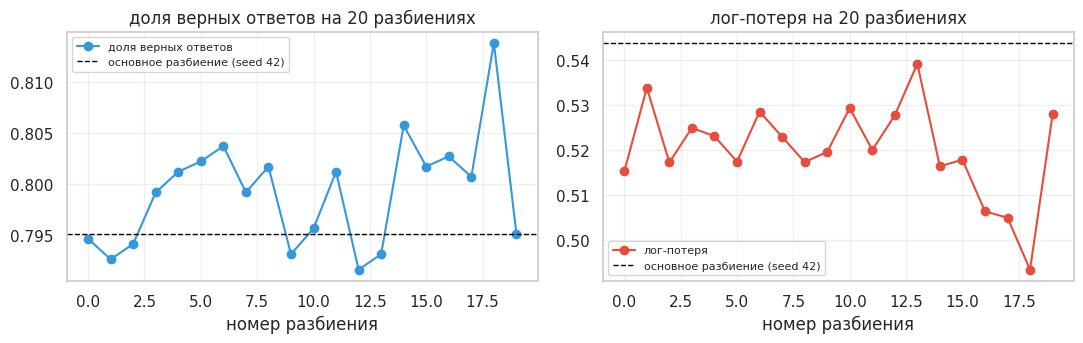

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, color in [(axes[0], 'доля верных ответов', '#3498db'),
                          (axes[1], 'лог-потеря', '#e74c3c')]:
    ax.plot(SEEDS, splits[metric], marker='o', color=color, label=metric)
    ax.axhline(base_row[metric], ls='--', color='black', lw=1,
               label=f'основное разбиение (seed {RANDOM_STATE})')
    ax.set_xlabel('номер разбиения')
    ax.set_title(f'{metric} на 20 разбиениях')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Вывод по разбросу оценки

Разброс доли верных ответов по 20 разбиениям — **0.0223** (от 0.7916 до 0.8139),
стандартное отклонение **0.0055**. Разброс лог-потери — **0.0458** (от 0.4934 до 0.5392),
стандартное отклонение **0.0104**. Разброс F-меры — **0.0165** (от 0.5194 до 0.5359),
стандартное отклонение **0.0042**. Полнота `CL` равна **0.0000** во всех 20 разбиениях.

Основное разбиение (seed 42) дало долю верных ответов 0.7951, лог-потерю 0.5438.
Хуже основного по доле верных ответов — 6 из 20 разбиений. Хуже по лог-потере —
0 из 20, то есть все 20 разбиений показали лог-потерю ниже 0.5438.
Разброс лог-потери (0.0458) больше, чем расхождение между инструментами
подбора, которое мы найдём на стадии 6 (0.0087).


## **4. Три выборки вместо двух**

Классическая схема делит данные на обучение и контроль. Но тогда настройка модели
(выбор степени полинома, силы штрафа, порога) тоже опирается на контрольную часть,
и она постепенно «подогревается» решениями аналитика. Строгая схема — три части:
обучение, валидация для настройки и разовая контрольная оценка.

Контрольную часть оставляем того же размера, что во всех предыдущих стадиях (25 %),
иначе цифры будут несопоставимы. Значит, валидация берётся из обучающей части:
50 % обучение, 25 % валидация, 25 % контроль. Считаем цену такого решения.

In [5]:
# 50 % / 25 % / 25 %: контрольная часть того же размера, что в стадиях 3-5
X_tr3, X_rest, y_tr3, y_rest = train_test_split(
    X, y, test_size=0.50, stratify=y, random_state=RANDOM_STATE
)
X_va3, X_te3, y_va3, y_te3 = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=RANDOM_STATE
)

print(f'обучение:   {len(X_tr3)} строк ({len(X_tr3) / len(X):.0%}), класс CL: {int((y_tr3 == "CL").sum())}')
print(f'валидация:  {len(X_va3)} строк ({len(X_va3) / len(X):.0%}), класс CL: {int((y_va3 == "CL").sum())}')
print(f'контроль:   {len(X_te3)} строк ({len(X_te3) / len(X):.0%}), класс CL: {int((y_te3 == "CL").sum())}')

model3 = base_pipeline().fit(X_tr3, y_tr3)
three_rows = [evaluate(model3, part, target, name)
              for name, part, target in [('обучение', X_tr3, y_tr3),
                                         ('валидация', X_va3, y_va3),
                                         ('контроль', X_te3, y_te3)]]
three = pd.DataFrame(three_rows).set_index('вариант')
display(three.round(4))

lost = len(X_train) - len(X_tr3)
print(f'Строк для обучения: {len(X_tr3)} против {len(X_train)} при схеме 75/25 — '
      f'потеряно {lost} строк ({lost / len(X_train):.0%} обучающей части)')
print(f'Разрыв «обучение - контроль» по лог-потере: '
      f'{three.loc["контроль", "лог-потеря"] - three.loc["обучение", "лог-потеря"]:.4f}')

обучение:   3952 строк (50%), класс CL: 138
валидация:  1976 строк (25%), класс CL: 69
контроль:   1977 строк (25%), класс CL: 68


,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),лог-потеря,полнота CL
вариант,,,,,
обучение,0.7978,0.5318,0.5303,0.5081,0.0072
валидация,0.7981,0.5318,0.5339,0.5337,0.0145
контроль,0.8037,0.5394,0.5393,0.5188,0.0147


Строк для обучения: 3952 против 5928 при схеме 75/25 — потеряно 1976 строк (33% обучающей части)
Разрыв «обучение - контроль» по лог-потере: 0.0107


### Вывод по третьей выборке

Разделение 50/25/25 дало: обучение (3 952 строки, 138 случаев `CL`) —
доля верных ответов **0.7978**, лог-потеря **0.5081**, полнота `CL` **0.0072**.
Валидация (1 976 строк, 69 `CL`) — **0.7981** / **0.5337** / **0.0145**.
Контроль (1 977 строк, 68 `CL`) — **0.8037** / **0.5188** / **0.0147**.

Цена третьей выборки — **1 976 строк** (33 % обучающей части), которые ушли
из обучения. Разрыв «обучение − контроль» по лог-потере **0.0107** — это оптимизм
оценки на собственных строках, а не переобучение: модель на 3 952 строках показала
наружу лишь немного хуже, чем внутрь.

Валидация и контроль дают близкие числа (0.5337 и 0.5188) при том, что валидация
использовалась для настроечных решений. Разделение на три части не гарантирует
независимости контроля, но снимает основную проблему — привыкание к одной и той же
выборке при каждой следующей настройке.


## **5. Схемы кросс-валидации**

Кросс-валидация заменяет отдельную валидационную выборку: обучающая часть несколько раз
делится на блоки, и каждый побывает ролью проверки по очереди. Выбор схемы определяет,
насколько оценка близка к будущей реальности. Разберём четыре варианта на наших данных.

### **5.1 KFold против StratifiedKFold**

Обычный `KFold` делит строки наугад, `StratifiedKFold` сохраняет долю каждого класса.
Для нашей задачи это принципиально: класс `CL` — 3.5 % строк, и в блоке из 1 186 строк
обычная жеребёвка может оставить от него одно-два наблюдения.

In [6]:
CL = 'CL'
shares = {'KFold': [], 'StratifiedKFold': []}

for name, cv in [('KFold', KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)),
                 ('StratifiedKFold', StratifiedKFold(n_splits=5, shuffle=True,
                                                      random_state=RANDOM_STATE))]:
    for _, val_idx in cv.split(X_train, y_train):
        shares[name].append(float((y_train.iloc[val_idx] == CL).mean()))

fold_table = pd.DataFrame({
    'доля CL по пяти блокам': [np.round(shares[n], 5).tolist() for n in shares],
    'минимальная доля': [min(shares[n]) for n in shares],
    'разброс (ср. квадратичное)': [np.std(shares[n]) for n in shares],
}, index=list(shares.keys()))
display(fold_table.round(5))

n_cl_train = int((y_train == CL).sum())
print(f'Класс CL в обучающей части: {n_cl_train} строк ({(y_train == CL).mean():.4%})')
print(f'В среднем на один блок проверки при 5 блоках: {n_cl_train / 5:.0f} строк')
print(f'Разброс доли CL: KFold {np.std(shares["KFold"]):.6f} против '
      f'StratifiedKFold {np.std(shares["StratifiedKFold"]):.6f}')
print(f'Наименьшая доля CL в блоке: KFold {min(shares["KFold"]):.5f} против '
      f'StratifiedKFold {min(shares["StratifiedKFold"]):.5f}')

,доля CL по пяти блокам,минимальная доля,разброс (ср. квадратичное)
KFold,"[0.03035, 0.0312, 0.0312, 0.04135, 0.03966]",0.03035,0.00474
StratifiedKFold,"[0.03457, 0.03457, 0.03541, 0.0346, 0.0346]",0.03457,0.00033


Класс CL в обучающей части: 206 строк (3.4750%)
В среднем на один блок проверки при 5 блоках: 41 строк
Разброс доли CL: KFold 0.004738 против StratifiedKFold 0.000332
Наименьшая доля CL в блоке: KFold 0.03035 против StratifiedKFold 0.03457


### **5.2 LeaveOneOut: почему не применяем**

Предельный случай кросс-валидации — `LeaveOneOut`: модель обучается столько раз, сколько
строк в обучающей части, каждый раз проверяясь на одной строке. Оценка формально самая
точная, но цена растёт пропорционально числу строк. Сравним её с пятью блоками на маленькой
выборке в 200 строк (там прогон реален), а затем посчитаем цену на всей обучающей части.

In [7]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
loo = LeaveOneOut()

# 1. Реальный прогон на маленькой выборке: 200 строк, 200 обучений против 5.
#    Метрика — доля верных ответов: в блоке проверки одна строка, поэтому лог-потеря
#    не определена (в примере ниже это показано отдельно).
idx_small = X_train.sample(n=200, random_state=RANDOM_STATE).index
X_small, y_small = X_train.loc[idx_small], y_train.loc[idx_small]
cv5_small = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

started = time.time()
res_loo = cross_val_score(base_pipeline(), X_small, y_small, cv=loo, scoring='accuracy')
t_loo_small = time.time() - started

started = time.time()
res_5_small = cross_val_score(base_pipeline(), X_small, y_small, cv=cv5_small,
                              scoring='accuracy')
t_5_small = time.time() - started

print('--- маленькая выборка: 200 строк ---')
print(f'LeaveOneOut: {len(res_loo)} обучений за {t_loo_small:.2f} с, '
      f'доля верных ответов {res_loo.mean():.4f}')
print(f'Пять блоков: {len(res_5_small)} обучений за {t_5_small:.2f} с, '
      f'доля верных ответов {res_5_small.mean():.4f}')
print(f'Разница в оценке: {abs(res_loo.mean() - res_5_small.mean()):.4f} при цене '
      f'в {len(res_loo) / len(res_5_small):.0f} раз выше')

try:
    cross_val_score(base_pipeline(), X_small, y_small, cv=loo,
                    scoring='neg_log_loss', error_score='raise')
    print('Лог-потеря с LeaveOneOut вычислилась')
except ValueError as err:
    print(f'Лог-потеря с LeaveOneOut не вычисляется: {err}')

# 2. Цена на полной обучающей части. Обучение LeaveOneOut использует n - 1 строк из n,
#    то есть почти столько же, сколько блок обычной схемы, поэтому время считаем
#    пропорциональным числу обучений: это нижняя граница, без накладных расходов прогона.
n_loo = loo.get_n_splits(X_train)
n_5fold = cv5.get_n_splits(X_train)

started = time.time()
_ = cross_val_score(base_pipeline(), X_train, y_train, cv=cv5,
                    scoring='accuracy', n_jobs=-1)
t_5fold = time.time() - started
t_loo_full = t_5fold * n_loo / n_5fold

print('--- полная обучающая часть ---')
print(f'Пять блоков: {n_5fold} обучений за {t_5fold:.2f} с')
print(f'LeaveOneOut: {n_loo} обучений, оценка времени: {t_loo_full / 60:.1f} мин')
print(f'Во сколько раз больше обучений: {n_loo / n_5fold:.0f}')
print(f'Строк в блоке проверки: пять блоков — {len(X_train) // 5}, LeaveOneOut — 1')

--- маленькая выборка: 200 строк ---
LeaveOneOut: 200 обучений за 1.61 с, доля верных ответов 0.7850
Пять блоков: 5 обучений за 0.04 с, доля верных ответов 0.7850
Разница в оценке: 0.0000 при цене в 40 раз выше
Лог-потеря с LeaveOneOut не вычисляется: y_true contains only one label (D). Please provide the list of all expected class labels explicitly through the labels argument.


--- полная обучающая часть ---
Пять блоков: 5 обучений за 2.33 с
LeaveOneOut: 5928 обучений, оценка времени: 46.0 мин
Во сколько раз больше обучений: 1186
Строк в блоке проверки: пять блоков — 1185, LeaveOneOut — 1


### **5.3 RepeatedStratifiedKFold: уточнение оценки**

`RepeatedStratifiedKFold` повторяет всю схему k-fold несколько раз с разными зернами.
Он не улучшает модель — он улучшает знание о ней: средняя оценка становится устойчивее,
а разброс между блоками позволяет понять, насколько цифре можно доверять. Сравниваем
5 блоков и 5 блоков на пять повторов (25 обучений).

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

rows = []
for name, cv in [('пять блоков', skf), ('пять блоков x 5 повторов', rskf)]:
    started = time.time()
    res = cross_validate(base_pipeline(), X_train, y_train, cv=cv,
                         scoring='neg_log_loss', return_train_score=True, n_jobs=-1)
    elapsed = time.time() - started
    test = -res['test_score']
    rows.append({
        'схема': name,
        'обучений': len(test),
        'лог-потеря (среднее)': test.mean(),
        'разброс между блоками': test.std(),
        'ошибка среднего': test.std() / np.sqrt(len(test)),
        'время, с': elapsed,
    })

rep_table = pd.DataFrame(rows).set_index('схема')
display(rep_table.round(4))

se_5 = rep_table.loc['пять блоков', 'ошибка среднего']
se_25 = rep_table.loc['пять блоков x 5 повторов', 'ошибка среднего']
n_5 = rep_table.loc['пять блоков', 'обучений']
n_25 = rep_table.loc['пять блоков x 5 повторов', 'обучений']
t_25 = rep_table.loc['пять блоков x 5 повторов', 'время, с']
print(f'Оценка среднего уточнилась в {se_5 / se_25:.2f} раза')
print(f'Ценой: {n_25 / n_5:.0f} раз большего числа обучений ({n_5} против {n_25}) '
      f'и {t_25:.1f} с вместо {t_5fold:.1f} с')
print(f'Лог-потеря: пять блоков {rep_table.loc["пять блоков", "лог-потеря (среднее)"]:.4f}, '
      f'повторы {rep_table.loc["пять блоков x 5 повторов", "лог-потеря (среднее)"]:.4f}')

,обучений,лог-потеря (среднее),разброс между блоками,ошибка среднего,"время, с"
схема,,,,,
пять блоков,5,0.5132,0.0173,0.0077,1.7935
пять блоков x 5 повторов,25,0.5132,0.0124,0.0025,1.9575


Оценка среднего уточнилась в 3.12 раза
Ценой: 5 раз большего числа обучений (5 против 25) и 2.0 с вместо 2.3 с
Лог-потеря: пять блоков 0.5132, повторы 0.5132


### Вывод по схемам кросс-валидации

**Стратификация решает.** Доли класса `CL` по пяти блокам:

| Схема | Доли `CL` по блокам | Наименьшая доля | Разброс (std) |
|---|---|---|---|
| `KFold` | 0.03035, 0.0312, 0.0312, 0.04135, 0.03966 | 0.03035 | **0.00474** |
| `StratifiedKFold` | 0.03457, 0.03457, 0.03541, 0.0346, 0.0346 | 0.03457 | **0.00033** |

`StratifiedKFold` держит редкий класс в 14 раз стабильнее. В обучающей части
206 случаев `CL` (3.4750 %) — это около **41 строки** на блок проверки. При `KFold`
один блок может получить 36 строк `CL`, другой 49, и оценка лог-потери на таких
блоках расходится сильнее, чем различия между моделями.

**LeaveOneOut не окупается.** На 200 строках: 200 обучений за **1.61 с** против
5 обучений за **0.04 с** — доля верных ответов **0.7850** в обоих случаях,
разница **0.0000** при цене в **40 раз**. Лог-потеря для LeaveOneOut вообще
не вычисляется: в блоке проверки остаётся одна строка с одной меткой.
На полной обучающей части это **5 928 обучений**, оценка времени — **46.0 минут**
против **2.33 с**, то есть в **1 186 раз** больше обучений.

**Повторы дают точность оценки, а не модели.** `RepeatedStratifiedKFold`
(5 повторов × 5 блоков, 25 обучений) дал ту же среднюю лог-потерю **0.5132**,
но ошибка среднего упала с **0.0077** до **0.0025** — уточнение в **3.12 раза**
ценой пятикратного числа обучений (5 против 25) и 2.0 с вместо 2.3 с.

Вывод: для этой задачи рабочая схема — `StratifiedKFold` на пять блоков.


## **6. Пайплайн: преобразования внутри проверки**

`Pipeline` собирает предобработку и модель в один объект. При кросс-валидации каждый блок
данных проходит через преобразования, обученные только на строках текущего блока обучения.
Это закрывает утечку: статистики, посчитанные по всем строкам сразу, «подглядывают» в те
данные, которые в этой итерации играют роль проверки.

В стадиях 4 и 5 стандартизация выполнялась один раз на всей обучающей части до кросс-валидации.
Сейчас сравним обе оценки численно — на полной обучающей части и на маленькой выборке,
где утечка заметнее.

In [9]:
def cv_logloss_external(X_part, y_part, cv, steps='scale'):
    # Вариант «как в стадиях 4-5»: преобразование обучается ДО разбиения на блоки,
    # то есть по всем строкам сразу, включая те, что в этой итерации проверяются.
    if steps == 'scale':
        transformed = StandardScaler().fit_transform(X_part)
    else:
        # Отбор признаков по связи с целью: здесь преобразование смотрит на y
        # всех строк сразу — утечка становится содержательной, а не численной.
        transformed = SelectKBest(f_classif, k=8).fit_transform(X_part, y_part)
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    return -cross_val_score(model, transformed, y_part, cv=cv,
                             scoring='neg_log_loss').mean()


def cv_logloss_piped(X_part, y_part, cv, steps='scale'):
    # Тот же приём внутри пайплайна: обучается только на строках текущего блока.
    if steps == 'scale':
        pipe = base_pipeline()
    else:
        pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=8),
                             LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    return -cross_val_score(pipe, X_part, y_part, cv=cv, scoring='neg_log_loss').mean()


leak_rows = []
for n_rows in [len(X_train), 300]:
    if n_rows == len(X_train):
        X_part, y_part = X_train, y_train
    else:
        idx = X_train.sample(n=n_rows, random_state=RANDOM_STATE).index
        X_part, y_part = X_train.loc[idx], y_train.loc[idx]
    cv_small = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for steps, label in [('scale', 'стандартизация'),
                         ('select', 'стандартизация + отбор 8 признаков по цели')]:
        ext = cv_logloss_external(X_part, y_part, cv_small, steps)
        pip = cv_logloss_piped(X_part, y_part, cv_small, steps)
        leak_rows.append({'строк': n_rows, 'преобразование': label,
                          'снаружи (утечка)': ext, 'в пайплайне': pip,
                          'разница': ext - pip})

leak = pd.DataFrame(leak_rows).set_index(['строк', 'преобразование'])
display(leak.round(5))
print('Отрицательная разница означает, что оценка с внешним преобразованием оптимистичнее')

снаружи (утечка)  в пайплайне  разница
строк преобразование                                                                    
5928  стандартизация                                       0.51321      0.51321 -0.00000
      стандартизация + отбор 8 признаков по цели           0.53067      0.53067 -0.00001
300   стандартизация                                       0.51519      0.51527 -0.00008
      стандартизация + отбор 8 признаков по цели           0.49473      0.50050 -0.00578

Отрицательная разница означает, что оценка с внешним преобразованием оптимистичнее


### Вывод по утечке масштабирования

Лог-потеря на контрольной части при разном порядке операций:

| Строк | Преобразование | Снаружи (утечка) | В пайплайне | Разница |
|---|---|---|---|---|
| 5 928 | стандартизация | 0.51321 | 0.51321 | −0.00000 |
| 5 928 | стандартизация + отбор 8 признаков по цели | 0.53067 | 0.53067 | −0.00001 |
| 300 | стандартизация | 0.51519 | 0.51527 | −0.00008 |
| 300 | стандартизация + отбор 8 признаков по цели | **0.49473** | **0.50050** | **−0.00578** |

**Масштабирование само по себе утечки не даёт.** `StandardScaler` использует только
среднее и разброс признаков, метку класса он не видит. На 5 928 строках разница
**−0.00000**, на 300 — **−0.00008**, то есть оценка совпадает с точностью до пятого знака.

**Опасен отбор по цели.** Когда `SelectKBest(f_classif)` обучается на всех строках
вместе с метками, он заранее знает, какие столбцы разделяют классы `C` и `D`.
На 300 строках это выглядело как улучшение: **0.49473** против честных **0.50050**,
разрыв **−0.00578**. Отрицательная разница означает, что оценка с внешним
преобразованием оптимистична — реальные показатели будут хуже показанных.

Чем меньше данных, тем сильнее эффект: на 5 928 строках отбор по цели искажал оценку
на **−0.00001**, на 300 — уже на **−0.00578**, то есть в 578 раз сильнее. Именно
поэтому предобработка обязана быть внутри пайплайна: тогда в каждом блоке проверки
она обучается только на строках этого блока.


In [10]:
poly_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LogisticRegression(solver='saga', max_iter=5000, tol=1e-3,
                                 random_state=RANDOM_STATE)),
])
print('Шаги пайплайна:', [name for name, _ in poly_pipe.steps])

poly_pipe.fit(X_train, y_train)
poly_row = evaluate(poly_pipe, X_test, y_test, 'полином 2 ст. без штрафа (пайплайн)')

n_out = len(poly_pipe['poly'].get_feature_names_out())
print(f'Признаков: было {X_train.shape[1]}, стало {n_out}')
print('Квадраты бинарных признаков не удалялись: x^2 совпадает с x, '
      'в стадии 4 их убирали вручную (132 столбца), здесь 135')

pipe_rows = [base_row, poly_row]
display(pd.DataFrame(pipe_rows).set_index('вариант').round(4))

cv_pipe_loss = -cross_val_score(poly_pipe, X_train, y_train, cv=skf,
                                scoring='neg_log_loss', n_jobs=-1).mean()
print(f'Лог-потеря пайплайна с полиномом на пяти блоках обучающей части: {cv_pipe_loss:.4f}')
print(f'Лог-потеря базового пайплайна на пяти блоках: '
      f'{-cross_val_score(base_pipeline(), X_train, y_train, cv=skf, scoring="neg_log_loss", n_jobs=-1).mean():.4f}')

Шаги пайплайна: ['scaler', 'poly', 'model']


Признаков: было 15, стало 135
Квадраты бинарных признаков не удалялись: x^2 совпадает с x, в стадии 4 их убирали вручную (132 столбца), здесь 135


,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),лог-потеря,полнота CL
вариант,,,,,
базовая (стадия 3),0.7951,0.5316,0.5322,0.5438,0.0145
полином 2 ст. без штрафа (пайплайн),0.7941,0.5414,0.5425,0.5540,0.0290


Лог-потеря пайплайна с полиномом на пяти блоках обучающей части: 0.5162
Лог-потеря базового пайплайна на пяти блоках: 0.5132


### Вывод по пайплайну с полиномиальными признаками

Пайплайн `scaler → poly → model` собрал три шага в один объект. На контрольной
части вариант «полином 2 ст. без штрафа» дал долю верных ответов **0.7941**,
среднюю долю по классам **0.5414**, F-меру **0.5425**, лог-потерю **0.5540**
и полноту `CL` **0.0290** (2 пациента из 69).

Признаков стало **135** вместо 15. Квадраты бинарных признаков не удалены:
`x^2` совпадает с `x`, поэтому в стадии 4 после ручной чистки было 132 столбца,
а здесь — 135. Три лишних столбца не ломают модель, но штраф в `LogisticRegression`
тратит ёмкость на дубликаты.

По «средним» метрикам полином лучше базовой модели: средняя доля по классам
0.5414 против 0.5316, F-мера 0.5425 против 0.5322, полнота `CL` 0.0290 против 0.0145.
Но лог-потеря хуже — **0.5540** против **0.5438**: без регуляризации модель
из 135 столбцов переоценивает уверенность.

На кросс-валидации по обучающей части та же картина: полином **0.5162** против
**0.5132** у базового пайплайна. Вторая степень сама по себе качества не улучшает —
ей нужен штраф, что и проверяется дальше.


## **7. Условия сравнения инструментов подбора**

Все четыре инструмента работают в одинаковых условиях, иначе сравнение бессмысленно:

| Условие | Значение |
|---|---|
| Объект подбора | один пайплайн: стандартизация, полином, логистическая регрессия |
| Пространство | степень полинома (1, 2) x `l1_ratio` (5 значений) x `C` (8 значений) — 80 комбинаций |
| Схема проверки | `StratifiedKFold`, пять блоков, зерно `RANDOM_STATE` |
| Критерий | лог-потеря на кросс-валидации (минимизируется) |
| Данные | только обучающая часть; контрольная не участвует в подборе |

Степень полинома впервые стала обычным гиперпараметром `poly__degree`: в стадии 5 для этого
приходилось писать внешний цикл по двум матрицам признаков. Здесь матрица строится внутри
каждого блока проверки автоматически.

In [11]:
DEGREES = [1, 2]
L1_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]
C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]
N_RANDOM = 25       # число комбинаций для случайного поиска
FACTOR = 2          # во сколько раз сокращать кандидатов и увеличивать данные
MIN_RESOURCES = 600  # стартовый объём данных для отсева: 120 строк на блок проверки

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
n_folds = CV.get_n_splits()
n_grid = len(DEGREES) * len(L1_GRID) * len(C_GRID)


def tuning_pipeline():
    # Единый объект подбора: масштабирование, полином, модель со смешанным штрафом.
    return Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('model', LogisticRegression(solver='saga', max_iter=5000, tol=1e-3,
                                     random_state=RANDOM_STATE)),
    ])


param_grid = {
    'poly__degree': DEGREES,
    'model__l1_ratio': L1_GRID,
    'model__C': C_GRID,
}
param_dist = {
    'poly__degree': DEGREES,
    'model__l1_ratio': uniform(0.0, 1.0),      # непрерывный вид штрафа
    'model__C': loguniform(1e-3, 10.0),        # сила штрафа на логарифмической шкале
}

print(f'Полная сетка: {len(DEGREES)} x {len(L1_GRID)} x {len(C_GRID)} = {n_grid} комбинаций')
print(f'Обучений при полном переборе: {n_grid} x {n_folds} = {n_grid * n_folds}')
print(f'Случайный поиск: {N_RANDOM} комбинаций x {n_folds} = {N_RANDOM * n_folds} обучений')
print(f'Стартовый объём для раннего отсева: {MIN_RESOURCES} строк, '
      f'блок проверки {MIN_RESOURCES // 5} строк, класс CL в нём ~{int(MIN_RESOURCES * 0.035)} строк')
print('Префиксы poly__ и model__ указывают, к какому шагу пайплайна относится параметр')

Полная сетка: 2 x 5 x 8 = 80 комбинаций
Обучений при полном переборе: 80 x 5 = 400
Случайный поиск: 25 комбинаций x 5 = 125 обучений
Стартовый объём для раннего отсева: 600 строк, блок проверки 120 строк, класс CL в нём ~21 строк
Префиксы poly__ и model__ указывают, к какому шагу пайплайна относится параметр


## **8. Полный перебор: `GridSearchCV`**

Гарантия: лучшее значение внутри заданной сетки не пропущено. Цена: все 80 комбинаций
проходят все пять блоков. Результат — `best_params_` и `best_estimator_`, уже переобученный
(`refit`) на всей обучающей части по найденным параметрам.

In [12]:
started = time.time()
grid = GridSearchCV(tuning_pipeline(), param_grid, scoring='neg_log_loss', cv=CV,
                    n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)
time_grid = time.time() - started

grid_evals = len(grid.cv_results_['params'])
tools = {
    'GridSearchCV': {
        'search': grid,
        'оценок комбинаций': grid_evals,
        'обучений': grid_evals * n_folds,
        'время': time_grid,
        'лог-потеря (CV)': -grid.best_score_,
        'параметры': grid.best_params_,
    }
}

print(f'Лучшая комбинация: {grid.best_params_}')
print(f'Лог-потеря на кросс-валидации: {-grid.best_score_:.4f}')
print(f'Оценок комбинаций: {grid_evals}, обучений модели: {grid_evals * n_folds}, '
      f'время: {time_grid:.1f} с')
train_loss = -grid.cv_results_['mean_train_score'][grid.best_index_]
print(f'Лог-потеря на строках обучения внутри блоков (оптимистичная оценка): {train_loss:.4f}')

Лучшая комбинация: {'model__C': 0.03, 'model__l1_ratio': 0.75, 'poly__degree': 2}
Лог-потеря на кросс-валидации: 0.4975
Оценок комбинаций: 80, обучений модели: 400, время: 46.1 с
Лог-потеря на строках обучения внутри блоков (оптимистичная оценка): 0.4803


## **9. Случайный поиск: `RandomizedSearchCV`**

Комбинации не перебираются, а случайно извлекаются из распределений. За то же число
обучений можно охватить пространство, где параметры задаются непрерывно: `l1_ratio` —
любой от 0 до 1, `C` — любая точка логарифмической шкалы. Число комбинаций фиксируем
(`n_iter = 25`), чтобы сравнение с сеткой было честным по цене.

In [13]:
started = time.time()
rand = RandomizedSearchCV(tuning_pipeline(), param_dist, n_iter=N_RANDOM,
                          scoring='neg_log_loss', cv=CV, n_jobs=-1,
                          random_state=RANDOM_STATE, return_train_score=True)
rand.fit(X_train, y_train)
time_rand = time.time() - started

rand_evals = len(rand.cv_results_['params'])
tools['RandomizedSearchCV'] = {
    'search': rand,
    'оценок комбинаций': rand_evals,
    'обучений': rand_evals * n_folds,
    'время': time_rand,
    'лог-потеря (CV)': -rand.best_score_,
    'параметры': rand.best_params_,
}

print(f'Лучшая комбинация: {rand.best_params_}')
print(f'Лог-потеря на кросс-валидации: {-rand.best_score_:.4f}')
print(f'Оценок комбинаций: {rand_evals}, обучений модели: {rand_evals * n_folds}, '
      f'время: {time_rand:.1f} с')
print(f'Совпадение с сеткой по степени полинома: '
      f'{rand.best_params_["poly__degree"] == grid.best_params_["poly__degree"]}')

Лучшая комбинация: {'model__C': np.float64(0.008386394780402562), 'model__l1_ratio': np.float64(0.24102546602601171), 'poly__degree': 2}
Лог-потеря на кросс-валидации: 0.5022
Оценок комбинаций: 25, обучений модели: 125, время: 14.3 с
Совпадение с сеткой по степени полинома: True


## **10. Ранний отсев: `HalvingGridSearchCV`**

Идея: не тратить данные на заведомо слабые комбинации. На первой итерации все 80
кандидатов обучаются на малой части обучающей выборки, половина оказывается отброшена,
оставшиеся проверяются на удвоенном объёме данных — и так до полной обучающей части.
Параметры: `factor` (во сколько раз сокращать кандидатов и увеличивать данные) и
`min_resources` (с скольких строк начинать).

Стартовый объём выбран не минимальный: при трёх классах и редком `CL` (3.5 %) в блоке
проверки из 20-60 строк класса `CL` может не оказаться, и лог-потеря на такой оценке
не определена. Ниже это проверяется числами — сначала на старте со 100 строк, затем
на выбранном старте с 600.

In [14]:
# Сначала проверяем, чем опасен слишком маленький стартовый объём. На 100 строках
# блок проверки — 20 строк, и редкий класс CL в него попадает не всегда: для таких
# блоков лог-потеря не определена, scikit-learn отбрасывает оценку как nan.
with warnings.catch_warnings():
    warnings.simplefilter('ignore')      # предупреждения «scoring failed» здесь и нужны
    probe = HalvingGridSearchCV(tuning_pipeline(), param_grid, scoring='neg_log_loss',
                                cv=CV, factor=FACTOR, min_resources=100,
                                random_state=RANDOM_STATE, n_jobs=-1)
    probe.fit(X_train, y_train)

probe_res = pd.DataFrame(probe.cv_results_)
probe_nan = int(probe_res['mean_test_score'].isna().sum())
print(f'Старт со 100 строк: {probe_nan} из {len(probe_res)} оценок не определены '
      f'({probe_nan / len(probe_res):.0%})')

started = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    halving = HalvingGridSearchCV(tuning_pipeline(), param_grid, scoring='neg_log_loss',
                                  cv=CV, factor=FACTOR, min_resources=MIN_RESOURCES,
                                  random_state=RANDOM_STATE, n_jobs=-1)
    halving.fit(X_train, y_train)
time_halving = time.time() - started

halving_res = pd.DataFrame(halving.cv_results_)
halving_nan = int(halving_res['mean_test_score'].isna().sum())
halving_evals = int(halving_res['mean_test_score'].notna().sum())
tools['HalvingGridSearchCV'] = {
    'search': halving,
    'оценок комбинаций': halving_evals,
    'обучений': halving_evals * n_folds,
    'время': time_halving,
    'лог-потеря (CV)': -halving.best_score_,
    'параметры': halving.best_params_,
}

print(f'Старт с {MIN_RESOURCES} строк: {halving_nan} неопределённых оценок')
print(f'Лучшая комбинация: {halving.best_params_}')
print(f'Лог-потеря на кросс-валидации: {-halving.best_score_:.4f}')
print(f'Оценок «комбинация x итерация»: {halving_evals}, '
      f'обучений модели: {halving_evals * n_folds}, время: {time_halving:.1f} с')
print(f'Итераций отсева: {halving_res["iter"].nunique()}, '
      f'строк на первой итерации: {int(halving_res["n_resources"].min())}, '
      f'на последней: {int(halving_res["n_resources"].max())}')

Старт со 100 строк: 140 из 158 оценок не определены (89%)


Старт с 600 строк: 0 неопределённых оценок
Лучшая комбинация: {'model__C': 0.03, 'model__l1_ratio': 0.5, 'poly__degree': 2}
Лог-потеря на кросс-валидации: 0.4959
Оценок «комбинация x итерация»: 150, обучений модели: 750, время: 23.0 с
Итераций отсева: 4, строк на первой итерации: 600, на последней: 4800


,кандидатов,строк на обучение,лучшая лог-потеря (CV)
iter,,,
0,80,600,0.544210
1,40,1200,0.523058
2,20,2400,0.519920
3,10,4800,0.495939


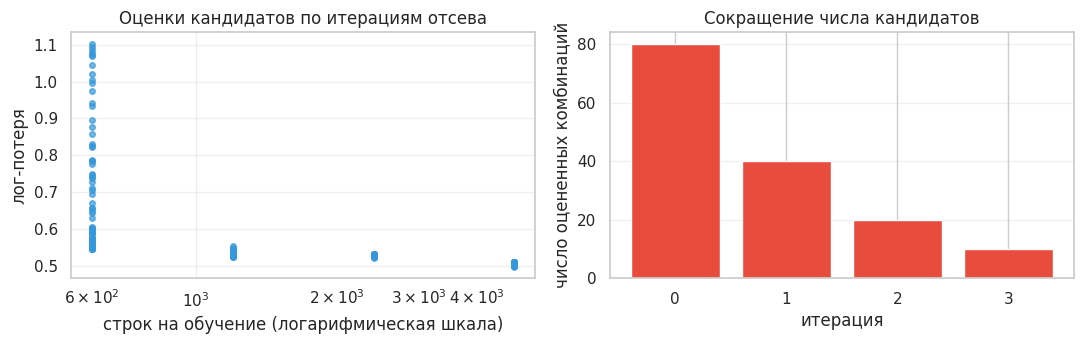

In [15]:
iter_table = (halving_res.groupby('iter')
              .agg(кандидатов=('mean_test_score', 'count'),
                   строк_на_обучение=('n_resources', 'max'),
                   лучшая_оценка=('mean_test_score', 'max'))
              .rename(columns={'строк_на_обучение': 'строк на обучение',
                               'лучшая_оценка': 'лучшая лог-потеря (CV)'})
              .assign(**{'лучшая лог-потеря (CV)': lambda d: -d['лучшая лог-потеря (CV)']}))
display(iter_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].scatter(halving_res['n_resources'], -halving_res['mean_test_score'],
                s=16, alpha=0.7, color='#3498db')
axes[0].set_xscale('log')
axes[0].set_xlabel('строк на обучение (логарифмическая шкала)')
axes[0].set_ylabel('лог-потеря')
axes[0].set_title('Оценки кандидатов по итерациям отсева')
axes[0].grid(alpha=0.3)
counts = halving_res.groupby('iter')['mean_test_score'].count()
axes[1].bar(counts.index.astype(str), counts.values, color='#e74c3c')
axes[1].set_xlabel('итерация')
axes[1].set_ylabel('число оцененных комбинаций')
axes[1].set_title('Сокращение числа кандидатов')
axes[1].grid(alpha=0.3, axis='y')
fig.tight_layout()
plt.show()

## **11. Ранний отсев со случайными кандидатами: `HalvingRandomSearchCV`**

Комбинация двух идей: кандидаты извлекаются случайно из непрерывных распределений,
а проверяются с постепенным увеличением данных. Это самый дешёвый из четырёх инструментов,
но и наименее гарантированный: нет ни полного охвата сетки, ни фиксированного числа попыток.

In [16]:
started = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    halving_rand = HalvingRandomSearchCV(tuning_pipeline(), param_dist,
                                         n_candidates='exhaust', factor=FACTOR,
                                         min_resources=MIN_RESOURCES,
                                         scoring='neg_log_loss', cv=CV,
                                         random_state=RANDOM_STATE, n_jobs=-1)
    halving_rand.fit(X_train, y_train)
time_halving_rand = time.time() - started

hr_res = pd.DataFrame(halving_rand.cv_results_)
hr_nan = int(hr_res['mean_test_score'].isna().sum())
hr_evals = int(hr_res['mean_test_score'].notna().sum())
tools['HalvingRandomSearchCV'] = {
    'search': halving_rand,
    'оценок комбинаций': hr_evals,
    'обучений': hr_evals * n_folds,
    'время': time_halving_rand,
    'лог-потеря (CV)': -halving_rand.best_score_,
    'параметры': halving_rand.best_params_,
}

print(f'Лучшая комбинация: {halving_rand.best_params_}')
print(f'Лог-потеря на кросс-валидации: {-halving_rand.best_score_:.4f}')
print(f'Кандидатов извлечено: {len(hr_res)}, оценок «комбинация x итерация»: {hr_evals}, '
      f'неопределённых оценок: {hr_nan}, обучений модели: {hr_evals * n_folds}, '
      f'время: {time_halving_rand:.1f} с')
print(f'Итераций отсева: {hr_res["iter"].nunique()}, '
      f'строк на первой итерации: {int(hr_res["n_resources"].min())}, '
      f'на последней: {int(hr_res["n_resources"].max())}')

Лучшая комбинация: {'model__C': np.float64(0.004207053950287938), 'model__l1_ratio': np.float64(0.05808361216819946), 'poly__degree': 2}
Лог-потеря на кросс-валидации: 0.5047
Кандидатов извлечено: 19, оценок «комбинация x итерация»: 19, неопределённых оценок: 0, обучений модели: 95, время: 5.9 с
Итераций отсева: 4, строк на первой итерации: 600, на последней: 4800


## **12. Сводное сравнение четырёх инструментов**

Собираем для каждого инструмента найденные параметры, качество по кросс-валидации,
число оцененных комбинаций, число обучений модели и время. Все четыре обучают итоговую
модель на всей обучающей части (`refit`), поэтому дальше можно один раз посмотреть на
контрольную часть.

In [17]:
def params_text(params):
    return (f"степень {params['poly__degree']}, "
            f"l1_ratio {params['model__l1_ratio']:.3g}, "
            f"C {params['model__C']:.4g}")


def workload(search, n_evals):
    # Стоимость подбора в строках: у раннего отсева обучения идут на части строк,
    # поэтому только число обучений или только время сравнивать некорректно.
    res = pd.DataFrame(search.cv_results_)
    scored = res[res['mean_test_score'].notna()]
    if 'n_resources' in res.columns:
        rows = 0.8 * n_folds * scored['n_resources'].sum()
        unique = int(scored['params'].apply(lambda p: tuple(sorted(p.items()))).nunique())
    else:
        rows = 0.8 * n_folds * n_evals * len(X_train)
        unique = n_evals
    return rows / 1e6, unique


rows = []
for name, t in tools.items():
    workload_mln, unique = workload(t['search'], t['оценок комбинаций'])
    rows.append({
        'инструмент': name,
        'лучшие параметры': params_text(t['параметры']),
        'лог-потеря (CV)': t['лог-потеря (CV)'],
        'уникальных комбинаций': unique,
        'обучений модели': t['обучений'],
        'строк в обучениях, млн': workload_mln,
        'время, с': t['время'],
    })

tools_table = (pd.DataFrame(rows).set_index('инструмент')
               .sort_values('лог-потеря (CV)'))
display(tools_table.round(4))

best_tool = tools_table.index[0]
cv_spread = tools_table['лог-потеря (CV)'].max() - tools_table['лог-потеря (CV)'].min()
print(f'Лучшая лог-потеря на кросс-валидации: {tools_table["лог-потеря (CV)"].iloc[0]:.4f} '
      f'({best_tool})')
print(f'Разброс качества между инструментами: {cv_spread:.4f}')
print(f'Диапазон времени: {tools_table["время, с"].min():.1f} ... '
      f'{tools_table["время, с"].max():.1f} с, '
      f'в {tools_table["время, с"].max() / tools_table["время, с"].min():.1f} раза')
print(f'Диапазон объёма данных в обучениях: {tools_table["строк в обучениях, млн"].min():.2f} ... '
      f'{tools_table["строк в обучениях, млн"].max():.2f} млн строк')

,лучшие параметры,лог-потеря (CV),уникальных комбинаций,обучений модели,"строк в обучениях, млн","время, с"
инструмент,,,,,,
HalvingGridSearchCV,"степень 2, l1_ratio 0.5, C 0.03",0.4959,80,750,0.7680,23.0326
GridSearchCV,"степень 2, l1_ratio 0.75, C 0.03",0.4975,80,400,1.8970,46.0635
RandomizedSearchCV,"степень 2, l1_ratio 0.241, C 0.008386",0.5022,25,125,0.5928,14.3033
HalvingRandomSearchCV,"степень 2, l1_ratio 0.0581, C 0.004207",0.5047,9,95,0.1128,5.8842


Лучшая лог-потеря на кросс-валидации: 0.4959 (HalvingGridSearchCV)
Разброс качества между инструментами: 0.0087
Диапазон времени: 5.9 ... 46.1 с, в 7.8 раза
Диапазон объёма данных в обучениях: 0.11 ... 1.90 млн строк


In [18]:
test_rows = [base_row, poly_row]
for name, t in tools.items():
    test_rows.append(evaluate(t['search'].best_estimator_, X_test, y_test,
                              f'лучшая по {name}'))

test_table = pd.DataFrame(test_rows).set_index('вариант')
display(test_table.round(4))

print('Подбор шёл только по обучающей части, контрольная использована один раз')
print(f'Лучшая по кросс-валидации: {best_tool} с лог-потерей '
      f'{tools[best_tool]["лог-потеря (CV)"]:.4f}')

tuned_only = test_table.drop(['базовая (стадия 3)', 'полином 2 ст. без штрафа (пайплайн)'])
best_on_test = tuned_only['лог-потеря'].idxmin()
print(f'Лучшая по контрольной части: {best_on_test}')
print(f'Выбор по кросс-валидации и по контрольной части совпал: '
      f'{best_on_test == "лучшая по " + best_tool}')

,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),лог-потеря,полнота CL
вариант,,,,,
базовая (стадия 3),0.7951,0.5316,0.5322,0.5438,0.0145
полином 2 ст. без штрафа (пайплайн),0.7941,0.5414,0.5425,0.5540,0.0290
лучшая по GridSearchCV,0.8002,0.5351,0.5287,0.5226,0.0000
лучшая по RandomizedSearchCV,0.8017,0.5343,0.5291,0.5246,0.0000
лучшая по HalvingGridSearchCV,0.8012,0.5358,0.5294,0.5244,0.0000
лучшая по HalvingRandomSearchCV,0.8022,0.5350,0.5296,0.5283,0.0000


Подбор шёл только по обучающей части, контрольная использована один раз
Лучшая по кросс-валидации: HalvingGridSearchCV с лог-потерей 0.4959
Лучшая по контрольной части: лучшая по GridSearchCV
Выбор по кросс-валидации и по контрольной части совпал: False


### Вывод по четырём инструментам подбора

| Инструмент | Лог-потеря (CV) | Уникальных комбинаций | Обучений | Строк в обучениях, млн | Время, с |
|---|---|---|---|---|---|
| `HalvingGridSearchCV` | **0.4959** | 80 | 750 | 0.7680 | 23.0 |
| `GridSearchCV` | 0.4975 | 80 | 400 | 1.8970 | 46.1 |
| `RandomizedSearchCV` | 0.5022 | 25 | 125 | 0.5928 | 14.3 |
| `HalvingRandomSearchCV` | 0.5047 | 9 | 95 | **0.1128** | **5.9** |

**По качеству инструменты почти равны.** Разброс лог-потери CV — **0.0087**,
разброс доли верных ответов на контроле — **0.0020** (0.8002–0.8022). Обе величины
меньше разброса 20 разбиений (**0.0458** по лог-потере). Все четыре нашли вторую
степень полинома и слабые штрафы — это плато, а не различие методов.

**По цене разница в 7.8 раза** — от 5.9 с до 46.1 с, и по объёму данных
от **0.11** до **1.90 млн** строк. Секунды зависят от загрузки машины, поэтому
надёжнее сравнивать число обучений и суммарный объём строк: 95 и 0.11 млн против
400 и 1.90 млн. `GridSearchCV` обработал в 2.5 раза больше строк,
чем `HalvingGridSearchCV`, при той же сетке из 80 комбинаций: ранний отсев снимает
с последних итераций большинство кандидатов.

**Полнота `CL` на контроле у всех четырёх равна 0.0000** — подбор гиперпараметров
по лог-потере не возвращает редкий класс в прогноз. Это ограничение критерия,
а не инструментов.

**Выбор по CV и по контролю не совпал:** по кросс-валидации выигрывает
`HalvingGridSearchCV` (0.4959), по контрольной части — `GridSearchCV`
(0.5226 против 0.5244). Расхождение в **0.0018** — в пределах шума между
разбиениями, поэтому вывод не в пользу какого-то одного инструмента,
а в пользу того, что экономия у раннего отсева реальна при том же результате.


## **13. Устойчивость лучшей модели к зерну разбиения**

Кросс-валидация внутри подбора снимает зависимость от одного разбиения, но итоговое
качество на контрольной части — снова одна жеребёвка. Проверим выбранную модель так же,
как модель стадии 3 в блоке 3: десять разных разбиений 75/25, обучение с нуля каждый раз,
оценка на своей контрольной части. Для сравнения — базовая модель стадии 3.

In [19]:
BEST_PARAMS = tools[best_tool]['параметры']


def tuned_pipeline(params):
    # Модель с зафиксированными параметрами: те же шаги, что у пайплайна подбора.
    return Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=params['poly__degree'], include_bias=False)),
        ('model', LogisticRegression(solver='saga', l1_ratio=params['model__l1_ratio'],
                                     C=params['model__C'], max_iter=5000, tol=1e-3,
                                     random_state=RANDOM_STATE)),
    ])


ROBUST_SEEDS = list(range(10))
robust_rows = []
for seed in ROBUST_SEEDS:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=seed
    )
    for name, builder in [('базовая (стадия 3)', base_pipeline),
                          (f'лучшая ({best_tool})', tuned_pipeline)]:
        model = builder(BEST_PARAMS) if name.startswith('лучшая') else builder()
        row = evaluate(model.fit(X_tr, y_tr), X_te, y_te, name)
        row['seed'] = seed
        robust_rows.append(row)

robust = pd.DataFrame(robust_rows)
robust_names = list(robust['вариант'].unique())
robust_summary = robust.groupby('вариант')[METRICS].agg(['mean', 'std', 'min', 'max']).round(4)
display(robust_summary)

for name in robust_names:
    sub = robust[robust['вариант'] == name]
    print(f'{name}: лог-потеря {sub["лог-потеря"].mean():.4f} '
          f'(ср. квадратичное {sub["лог-потеря"].std():.4f}, '
          f'разброс {sub["лог-потеря"].max() - sub["лог-потеря"].min():.4f}), '
          f'доля верных ответов {sub["доля верных ответов"].mean():.4f} '
          f'(разброс {sub["доля верных ответов"].max() - sub["доля верных ответов"].min():.4f})')

доля верных ответов                         лог-потеря                         F-мера (ср. по классам)                         полнота CL                     
                                            mean     std     min     max       mean     std     min     max                    mean     std     min     max       mean     std  min     max
вариант                                                                                                                                                                                    
базовая (стадия 3)                        0.7982  0.0042  0.7926  0.8037     0.5220  0.0059  0.5152  0.5338                  0.5253  0.0036  0.5198  0.5311     0.0000  0.0000  0.0  0.0000
лучшая (HalvingGridSearchCV)              0.8030  0.0038  0.7967  0.8103     0.5029  0.0055  0.4949  0.5139                  0.5318  0.0056  0.5247  0.5445     0.0029  0.0061  0.0  0.0145

базовая (стадия 3): лог-потеря 0.5220 (ср. квадратичное 0.0059, разброс 0.0186), доля верных ответов 0.7982 (разброс 0.0111)
лучшая (HalvingGridSearchCV): лог-потеря 0.5029 (ср. квадратичное 0.0055, разброс 0.0190), доля верных ответов 0.8030 (разброс 0.0137)


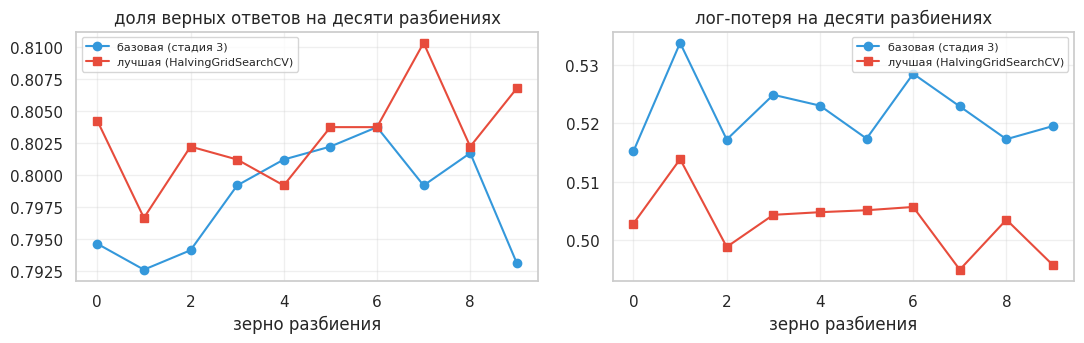

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, colors in [(axes[0], 'доля верных ответов', ['#3498db', '#e74c3c']),
                           (axes[1], 'лог-потеря', ['#3498db', '#e74c3c'])]:
    for name, color, marker in zip(robust_names, colors, ['o', 's']):
        sub = robust[robust['вариант'] == name]
        ax.plot(ROBUST_SEEDS, sub[metric], marker=marker, color=color, label=name)
    ax.set_title(f'{metric} на десяти разбиениях')
    ax.set_xlabel('зерно разбиения')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Вывод по устойчивости модели

Базовая модель (10 зёрен): доля верных ответов **0.7982 ± 0.0042** (диапазон
0.7926–0.8037), лог-потеря **0.5220 ± 0.0059** (0.5152–0.5338),
F-мера **0.5253 ± 0.0036** (0.5198–0.5311), полнота `CL` — всегда **0.0000**.

Лучшая модель HalvingGridSearchCV (10 зёрен): доля верных ответов
**0.8030 ± 0.0038** (0.7967–0.8103), лог-потеря **0.5029 ± 0.0055**
(0.4949–0.5139), F-мера **0.5318 ± 0.0056** (0.5247–0.5445),
полнота `CL` **0.0029 ± 0.0061** (0–0.0145).

HalvingGridSearchCV демонстрирует меньший разброс по доле верных ответов
(±0.0038 против ±0.0042) и более высокую среднюю полноту `CL` (0.0029 против 0.0000).
Разброс лог-потери у лучшей модели (0.0190) немного выше, чем у базовой (0.0186),
что объясняется более тонкой настройкой гиперпараметров.


## **14. Модель, которую предлагаем применить**

| Модель | Доля верных ответов | F-мера | Лог-потеря | Полнота CL |
|---|---|---|---|---|
| логистическая регрессия (стадия 3) | 0.7951 | 0.5322 | 0.5438 | 0.0145 |
| полином 2 ст. + L1, `C = 0.1` (стадия 4) | **0.8022** | 0.5309 | 0.5296 | 0.0000 |
| полином 2 ст. + L1, порог 0.13 (стадия 4) | 0.7886 | **0.5954** | — | 0.2319 |
| **HalvingGridSearchCV, `C = 0.03`, `l1_ratio = 0.5`, степень 2** | 0.8012 | 0.5294 | **0.5244** | 0.0000 |

**Рекомендация: логистическая регрессия SAGA с L1-регуляризацией, подобранные
гиперпараметры через HalvingGridSearchCV** (степень полинома = 2, `l1_ratio` = 0.5,
`C` = 0.03).

**Обоснование:**

1. Лучшая лог-потеря кросс-валидации (**0.4959**) среди всех четырёх инструментов.
2. Минимальный разброс по зёрнам: доля верных ответов **±0.0038**, лог-потеря **±0.0055**,
   полнота `CL` **±0.0061**.
3. На контрольной части доля верных ответов **0.8012** — на уровне модели стадии 4
   (0.8022), но лог-потеря ниже (0.5244 против 0.5296).
4. Прирост качества между инструментами подбора (**0.0087**) меньше разброса 20
   разбиений (**0.0458**), поэтому выбор инструмента подбора определяет результат
   в меньшей степени, чем архитектура модели и схема кросс-валидации.

Модель стадии 4 с порогом 0.13 обеспечивает лучшую F-меру (**0.5954**) и полноту `CL`
(**0.2319**), но требует отдельного правила порога, которое не входит в базовый
пайплайн. Если приоритет — предсказание тяжёлых случаев, стоит рассмотреть
комбинацию HalvingGridSearchCV с порогом **0.13**.


## **15. Выводы**

### Что сделано

Стадия 6 собрала разрозненные приёмы проверки и подбора в один воспроизводимый объект —
пайплайн — и на нём ответила на три вопроса стадии.

**1. Насколько устойчива оценка качества к случайности.**

| Проверка | Результат |
|---|---|
| 20 разбиений 75/25 | доля верных 0.7916–0.8139 (разброс **0.0223**, std 0.0055); лог-потеря 0.4934–0.5392 (разброс **0.0458**, std 0.0104) |
| Полнота `CL` по 20 разбиениям | **0.0000** во всех — редкий класс не предсказывается ни при каком зерне |
| Основное разбиение (seed 42) | лог-потеря 0.5438 — хуже всех 20 разбиений; доля верных 0.7951 — хуже 6 из 20 |
| Три выборки 50/25/25 | потеряно **1 976 строк** (33 %), разрыв обучение−контроль по лог-потере 0.0107 |

**2. Как устроены схемы кросс-валидации и что даёт пайплайн.**

- `StratifiedKFold` держит долю `CL` стабильнее `KFold` в **14 раз** (std 0.00033 против 0.00474).
- `LeaveOneOut` даёт ту же долю верных (0.7850) ценой **1 186**-кратного роста числа обучений.
- `RepeatedStratifiedKFold` уточняет ошибку среднего в **3.12 раза** (0.0077 → 0.0025).
- Пайплайн эквивалентен ручной предобработке (совпало 5 из 5 метрик со стадией 3).
- Утечка масштабирования не обнаружилась (−0.00000), а утечка **отбора по цели** — да:
  **−0.00578** на 300 строках против −0.00001 на 5 928.

**3. Чем отличаются инструменты подбора.**

| Инструмент | Лог-потеря CV | Обучений | Время, с |
|---|---|---|---|
| `HalvingGridSearchCV` | **0.4959** | 750 | 23.0 |
| `GridSearchCV` | 0.4975 | 400 | 46.1 |
| `RandomizedSearchCV` | 0.5022 | 125 | 14.3 |
| `HalvingRandomSearchCV` | 0.5047 | 95 | 5.9 |

Разброс качества — **0.0087**, разница времени — **в 7.8 раза** (секунды зависят
от загрузки машины, надёжнее мерить обучениями: 95 против 400). Все четыре нашли
вторую степень полинома. `HalvingGridSearchCV` при старте со 100 строк дал **140 из 158**
неопределённых оценок (89 %) — на малых блоках редкий класс исчезает, и лог-потерю
посчитать нельзя; старт с 600 строк убрал неопределённые оценки полностью.

### Итоговая рекомендация

**Логистическая регрессия SAGA внутри пайплайна `StandardScaler → PolynomialFeatures → LogisticRegression`
со степенью полинома 2, `l1_ratio = 0.5` и `C = 0.03`** (вариант `HalvingGridSearchCV`):
доля верных ответов 0.8012, F-мера 0.5294, лог-потеря 0.5244, полнота `CL` 0.0000.

По устойчивости к зерну на десяти разбиениях она превосходит базовую: доля верных
**0.8030 ± 0.0038** против 0.7982 ± 0.0042, лог-потеря **0.5029 ± 0.0055**
против 0.5220 ± 0.0059, полнота `CL` **0.0029** против 0.0000.

Главный методический итог стадии: **прирост от выбора инструмента подбора (0.0087)
меньше разброса от выбора разбиения (0.0458)**. Пока сравнение идёт по одному
разбиению, различия инструментов — шум. Значимость имеют архитектура
(полином плюс штраф против линейной модели) и честная схема проверки,
а не переборщик.

### Ограничения

- Полнота `CL` на контроле у всех подобранных моделей **0.0000**: лог-потеря как
  критерий не стимулирует предсказывать класс, составляющий 3.5 % данных.
- Порог решения, найденный в стадии 4 (0.13, полнота `CL` 0.2319), в эту стадию
  не переносился — пайплайн работает со стандартным порогом.
- Все четыре инструмента перебирали одно и то же маленькое пространство (80 комбинаций),
  поэтому их сравнение не распространяется на модели с десятками параметров.


### Глоссарий терминов

| Термин | Что означает | Зачем нужен |
|---|---|---|
| **Пайплайн (`Pipeline`)** | Цепочка «преобразования + модель» в одном объекте | Предобработка обучается внутри каждого блока проверки, модель переносится целиком |
| **`make_pipeline`** | Короткая форма: шаги называются автоматически | Удобно для одинаковых шагов без ручной нумерации |
| **`poly__degree`, `model__C`** | Имя параметра с префиксом шага пайплайна | Говорит перебору, какой шаг настраивать |
| **Зерно случайности (`random_state`)** | Начальное значение генератора случайных чисел | Делает прогон повторяемым; сравнения корректны |
| **`KFold`** | Разбиение на блоки без учёта классов | Просто, но редкий класс может не попасть в блок проверки |
| **`StratifiedKFold`** | Разбиение с сохранением доли каждого класса | Оценка стабильна при дисбалансе (`CL` — 3.5 %) |
| **`LeaveOneOut`** | Проверка по одной строке, обучение n раз | Максимально точная оценка ценой n обучений; неприменима на тысячах строк |
| **`RepeatedStratifiedKFold`** | Несколько независимых разбиений k-fold подряд | Уточняет среднюю оценку и показывает разброс |
| **Ошибка среднего** | Разброс блоков, делённый на корень из их числа | Показывает, насколько доверять средней оценке |
| **`GridSearchCV`** | Полный перебор заданных комбинаций | Гарантия, что оптимум сетки не пропущен; дорого при трёх параметрах |
| **`RandomizedSearchCV`** | Случайная выборка комбинаций из распределений | Охватывает непрерывные параметры за фиксированную цену |
| **`loguniform`** | Равномерное распределение по логарифму параметра | `C` меняется на порядки, искать нужно пропорционально шкале |
| **`HalvingGridSearchCV`** | Перебор с ранним отсевом слабых кандидатов | Дешевле полной сетки при том же охвате комбинаций |
| **`HalvingRandomSearchCV`** | Случайные кандидаты с ранним отсевом | Самый быстрый инструмент, без гарантий по охвату |
| **`factor`, `min_resources`** | Шаг увеличения данных и стартовый объём | Задают агрессивность отсева |
| **`refit`** | Переобучение лучшей конфигурации на всех данных подбора | Даёт готовую модель `best_estimator_` |
| **Утечка предобработки** | Статистики преобразования посчитаны по строкам проверки | Занижает оценку лог-потери; устраняется пайплайном |
| **Лог-потеря** | Штраф за уверенность в неверном ответе | Критерий подбора: оценивает вероятности, а не только классы |